In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ayush1220/cifar10")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'cifar10' dataset.
Path to dataset files: /kaggle/input/cifar10


In [2]:
!cp -r /kaggle/input/cifar10 /content/data

In [16]:
from torchvision.transforms import  v2
import torchvision.transforms as T
import torch
target_size = 224
transform_train = v2.Compose([
    v2.Resize((target_size,target_size)),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomCrop(224, padding=4),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
  ])

transform_test = v2.Compose([
    v2.Resize((target_size,target_size)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
  ])


In [5]:
import torchvision.datasets as datasets
train_dir = "/content/data/cifar10/train"
test_dir = "/content/data/cifar10/test"


train_data = datasets.ImageFolder(train_dir, transform=transform_train, target_transform=None)
test_data = datasets.ImageFolder(test_dir, transform=transform_test,target_transform=None)

print(f"Train data:\n{train_data}\nTest data:\n{test_data}")

Train data:
Dataset ImageFolder
    Number of datapoints: 50000
    Root location: /content/data/cifar10/train
    StandardTransform
Transform: Compose(
                 Resize(size=[224, 224], interpolation=InterpolationMode.BILINEAR, antialias=True)
                 RandomHorizontalFlip(p=0.5)
                 ToImage()
                 ToDtype(scale=True)
                 Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
           )
Test data:
Dataset ImageFolder
    Number of datapoints: 10000
    Root location: /content/data/cifar10/test
    StandardTransform
Transform: Compose(
                 Resize(size=[224, 224], interpolation=InterpolationMode.BILINEAR, antialias=True)
                 ToImage()
                 ToDtype(scale=True)
                 Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
           )


In [25]:
train_loader = torch.utils.data.DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=64, shuffle=False)

In [26]:
from torchvision import models

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
#

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [8]:
!pip install torchinfo

In [27]:
from torchinfo import summary
summary(model, input_size=(64, 3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [64, 1000]                --
├─Conv2d: 1-1                            [64, 64, 112, 112]        9,408
├─BatchNorm2d: 1-2                       [64, 64, 112, 112]        128
├─ReLU: 1-3                              [64, 64, 112, 112]        --
├─MaxPool2d: 1-4                         [64, 64, 56, 56]          --
├─Sequential: 1-5                        [64, 64, 56, 56]          --
│    └─BasicBlock: 2-1                   [64, 64, 56, 56]          --
│    │    └─Conv2d: 3-1                  [64, 64, 56, 56]          36,864
│    │    └─BatchNorm2d: 3-2             [64, 64, 56, 56]          128
│    │    └─ReLU: 3-3                    [64, 64, 56, 56]          --
│    │    └─Conv2d: 3-4                  [64, 64, 56, 56]          36,864
│    │    └─BatchNorm2d: 3-5             [64, 64, 56, 56]          128
│    │    └─ReLU: 3-6                    [64, 64, 56, 56]          --
│

In [28]:
len(train_data.classes)

10

(32, 32)


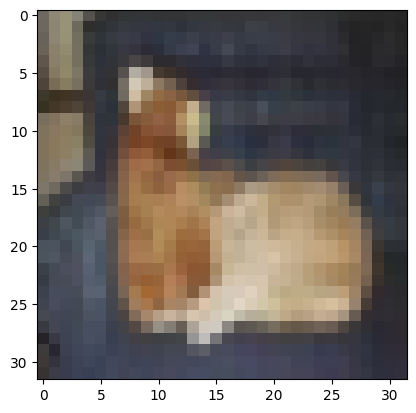

In [15]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open("/content/data/cifar10/train/cat/0002.png")
print(img.size)
imgplot = plt.imshow(img)
plt.show()

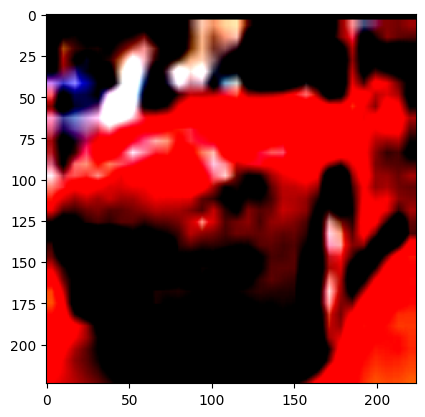

In [17]:
img = Image.open("/content/data/cifar10/train/automobile/0002.png")
img = transform_train(img)
img = img.permute(1,2,0)
plt.imshow(img)

In [30]:
num_ftrs = model.fc.in_features
model.fc = torch.nn.Linear(num_ftrs, len(train_data.classes))
model = model.to(device)

In [31]:
img = Image.open("/content/data/cifar10/train/automobile/0002.png")
img = transform_train(img)
img = img.to(device)
model.eval()
with torch.inference_mode():
  y_preds = model(img.unsqueeze(dim=0))
  y_pred_class = torch.argmax(torch.softmax(y_preds, dim=1), dim=1)
  print(f"Pred class: {train_data.classes[y_pred_class]}")
#

Pred class: horse


In [32]:
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                       mode='min',
                                                       factor=0.1,
                                                       patience=2)
#
#


In [33]:
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  acc = (correct / len(y_pred)) * 100
  return acc
#

In [34]:
def train_model(model: torch.nn.Module,
                train_dataloader: torch.utils.data.DataLoader,
                optimizer: torch.optim.Optimizer,
                loss_fn):
  model.train()
  train_loss, train_acc = 0, 0
  for batch, (X, y) in enumerate(train_dataloader):
    X, y = X.to(device), y.to(device)
    y_pred = model(X)
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += accuracy_fn(y_true=y,
                             y_pred=y_pred.argmax(dim=1))

  train_acc/= len(train_dataloader)
  train_loss/= len(train_dataloader)
  return train_loss, train_acc

In [35]:
from numpy.matrixlib import test
def test_model(model,loss_fn,test_dataloader,scheduler):
  model.eval()
  test_loss, test_acc = 0, 0
  with torch.inference_mode():
    for batch,(X,y) in enumerate(test_dataloader):
      X, y = X.to(device), y.to(device)
      test_pred = model(X)
      loss = loss_fn(test_pred, y)
      test_loss += loss.item()
      # test_pred_class = torch.argmax(torch.softmax(test_pred, dim=1), dim=1)
      test_acc += accuracy_fn(y_true=y,
                              y_pred=test_pred.argmax(dim=1))
  test_loss /= len(test_dataloader)
  test_acc /= len(test_dataloader)
  scheduler.step(test_loss)
  return test_loss, test_acc


In [36]:
import time
epochs = 10
start = time.time()
for epoch in range(epochs):
  train_loss, train_acc = train_model(model=model,
                                       train_dataloader=train_loader,optimizer=optimizer,loss_fn=loss_fn)
  test_loss, test_acc = test_model(model=model,loss_fn=loss_fn,
                                    test_dataloader=test_loader,scheduler=scheduler)
  print(f"Epoch: {epoch+1} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")
end = time.time()
print(f"Time taken: {end-start}")

Epoch: 1 | Train Loss: 0.3297 | Train Acc: 89.12% | Test Loss: 0.1972 | Test Acc: 93.30%
Epoch: 2 | Train Loss: 0.1344 | Train Acc: 95.62% | Test Loss: 0.1694 | Test Acc: 94.25%
Epoch: 3 | Train Loss: 0.0842 | Train Acc: 97.30% | Test Loss: 0.1753 | Test Acc: 94.13%
Epoch: 4 | Train Loss: 0.0617 | Train Acc: 98.02% | Test Loss: 0.1641 | Test Acc: 94.62%
Epoch: 5 | Train Loss: 0.0488 | Train Acc: 98.36% | Test Loss: 0.1680 | Test Acc: 94.51%
Epoch: 6 | Train Loss: 0.0422 | Train Acc: 98.60% | Test Loss: 0.1750 | Test Acc: 94.75%
Epoch: 7 | Train Loss: 0.0305 | Train Acc: 99.01% | Test Loss: 0.1730 | Test Acc: 94.84%
Epoch: 8 | Train Loss: 0.0141 | Train Acc: 99.59% | Test Loss: 0.1308 | Test Acc: 95.99%
Epoch: 9 | Train Loss: 0.0069 | Train Acc: 99.83% | Test Loss: 0.1269 | Test Acc: 96.23%
Epoch: 10 | Train Loss: 0.0050 | Train Acc: 99.90% | Test Loss: 0.1277 | Test Acc: 96.13%
Time taken: 3462.8607201576233


In [38]:
model.eval()
img = Image.open("/content/data/cifar10/train/deer/0001.png")
img = transform_test(img)
img = img.to(device)
with torch.inference_mode():
  y_preds = model(img.unsqueeze(dim=0))
  y_pred_class = torch.argmax(torch.softmax(y_preds, dim=1), dim=1)
  print(f"Pred class: {train_data.classes[y_pred_class]}")

Pred class: deer


In [39]:
!pip install torchmetrics mlxtend

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 10.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [40]:
import numpy as np
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

def make_confusion_matrix(model,test_dataloader):
  model.eval()
  y_true = []
  y_pred = []
  with torch.inference_mode():
    for inputs, labels in test_loader:
      inputs, labels = inputs.to(device), labels.to(device)
      outputs = model(inputs)
      #_, predicted = torch.max(outputs, 1)
      test_preds = torch.softmax(outputs.squeeze(), dim=1).argmax(dim=1)
      y_true.append(labels.cpu().numpy())
      y_pred.append(test_preds.cpu().numpy())

  y_pred = np.concatenate(y_pred)
  y_pred = torch.tensor(y_pred)

  test_data.targets = torch.tensor(test_data.targets)
  class_names = train_data.classes
  cm = ConfusionMatrix(num_classes=len(class_names), task = 'multiclass')
  cm_tensor = cm(preds= y_pred,target = test_data.targets)

  fig,ax = plot_confusion_matrix(conf_mat= cm_tensor.numpy(),
                                 class_names= class_names,
                                 figsize=(10,10))
#
#


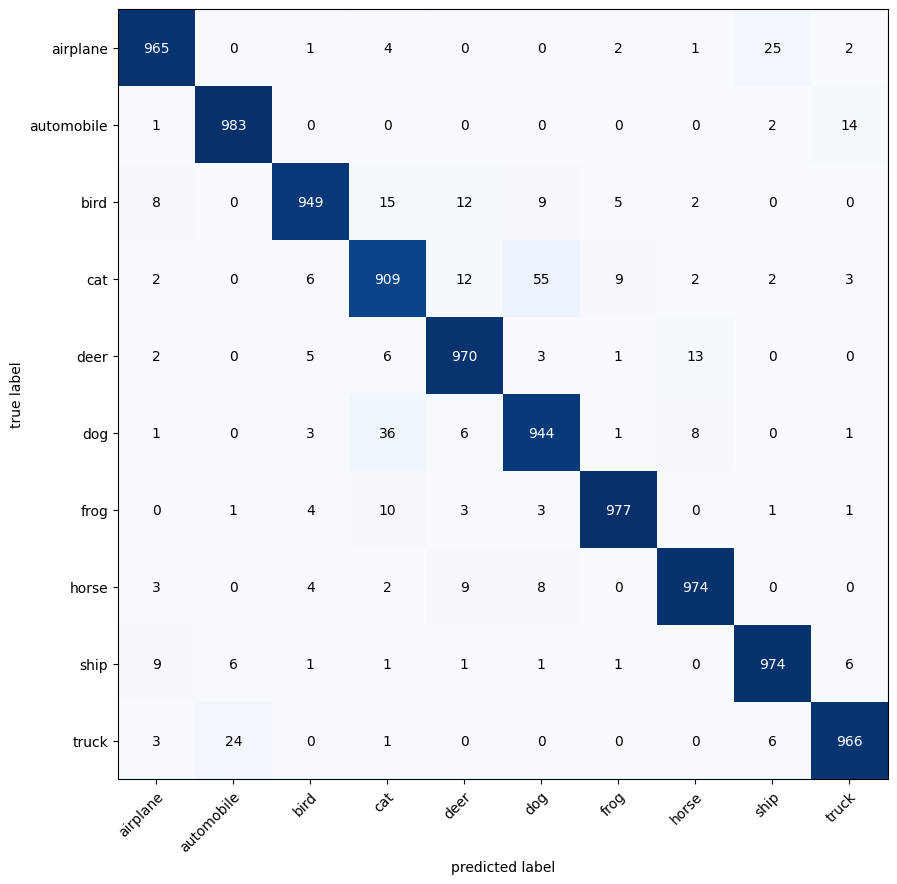

In [41]:
make_confusion_matrix(model,test_loader)
#

## Freezing Parameters


In [42]:
from torchvision import models

model_2 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for param in model_2.parameters():
  param.requires_grad = False

num_ftrs = model_2.fc.in_features
model_2.fc = torch.nn.Linear(num_ftrs, len(train_data.classes))

model_2 = model_2.to(device)
#
optimizer = torch.optim.Adam(model_2.fc.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                       mode='min',
                                                       factor=0.1,
                                                       patience=2)

In [43]:
import time
epochs = 10
start = time.time()
for epoch in range(epochs):
  train_loss, train_acc = train_model(model=model_2,
                                       train_dataloader=train_loader,optimizer=optimizer,loss_fn=loss_fn)
  test_loss, test_acc = test_model(model=model_2,loss_fn=loss_fn,
                                    test_dataloader=test_loader,scheduler=scheduler)
  print(f"Epoch: {epoch+1} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")
end = time.time()
print(f"Time taken: {end-start}")

Epoch: 1 | Train Loss: 1.5463 | Train Acc: 53.62% | Test Loss: 1.0904 | Test Acc: 69.90%
Epoch: 2 | Train Loss: 0.9557 | Train Acc: 72.89% | Test Loss: 0.8460 | Test Acc: 74.93%
Epoch: 3 | Train Loss: 0.8035 | Train Acc: 75.44% | Test Loss: 0.7496 | Test Acc: 76.46%
Epoch: 4 | Train Loss: 0.7324 | Train Acc: 76.64% | Test Loss: 0.7021 | Test Acc: 77.37%
Epoch: 5 | Train Loss: 0.6953 | Train Acc: 77.38% | Test Loss: 0.6687 | Test Acc: 77.93%
Epoch: 6 | Train Loss: 0.6668 | Train Acc: 78.17% | Test Loss: 0.6464 | Test Acc: 78.71%
Epoch: 7 | Train Loss: 0.6469 | Train Acc: 78.36% | Test Loss: 0.6315 | Test Acc: 79.10%
Epoch: 8 | Train Loss: 0.6344 | Train Acc: 78.83% | Test Loss: 0.6224 | Test Acc: 79.41%
Epoch: 9 | Train Loss: 0.6213 | Train Acc: 79.27% | Test Loss: 0.6138 | Test Acc: 79.41%
Epoch: 10 | Train Loss: 0.6081 | Train Acc: 79.57% | Test Loss: 0.6095 | Test Acc: 79.74%
Time taken: 2547.9739429950714


/tmp/ipykernel_825/3512094991.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_data.targets = torch.tensor(test_data.targets)


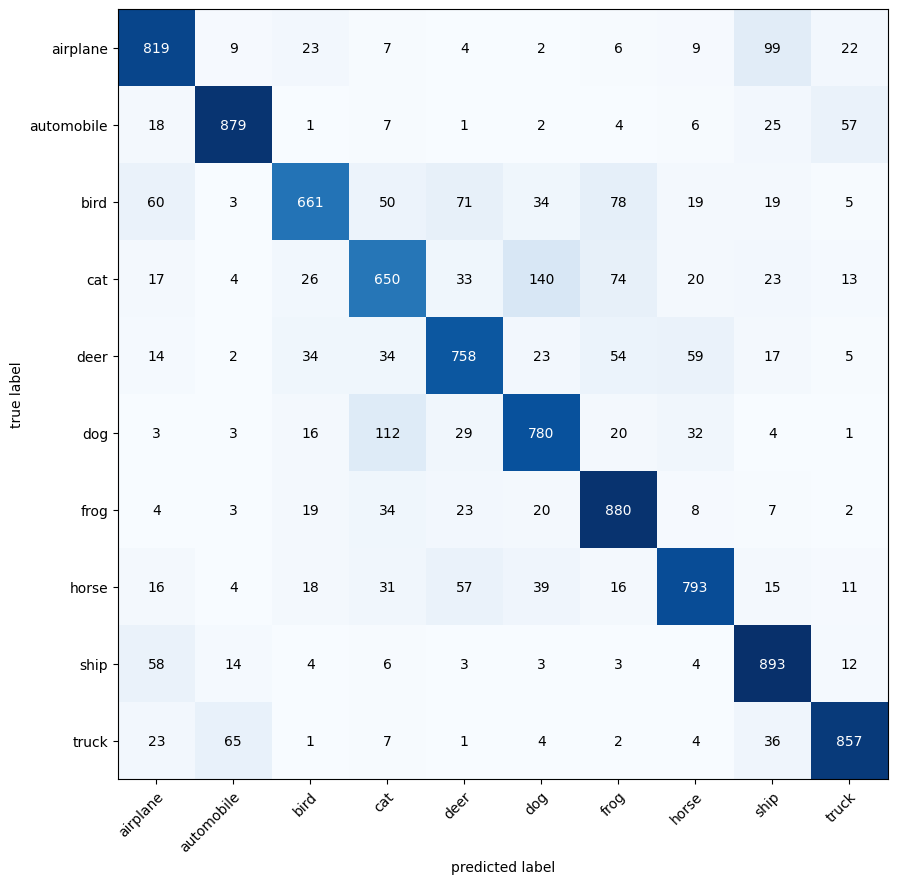

In [44]:
make_confusion_matrix(model_2,test_loader)